# Credit Risk Assestment

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# EDA

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [6]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [7]:
df["loan_status"].unique()

array([1, 0])

In [8]:
df["loan_status"].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

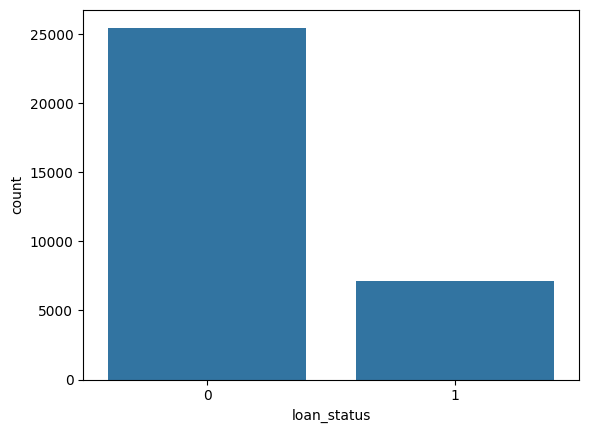

In [9]:
sns.countplot(x="loan_status",data=df)

In [10]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [11]:
num_cols = df.select_dtypes(include = np.number).columns
num_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

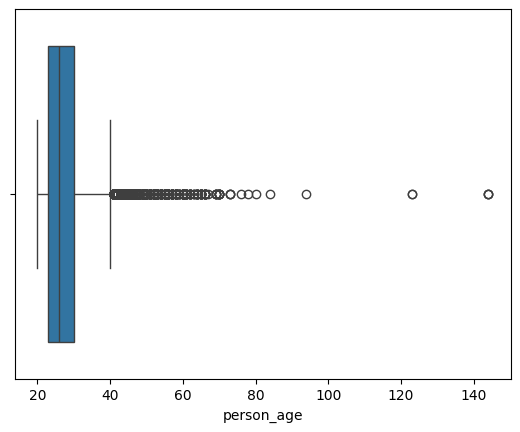

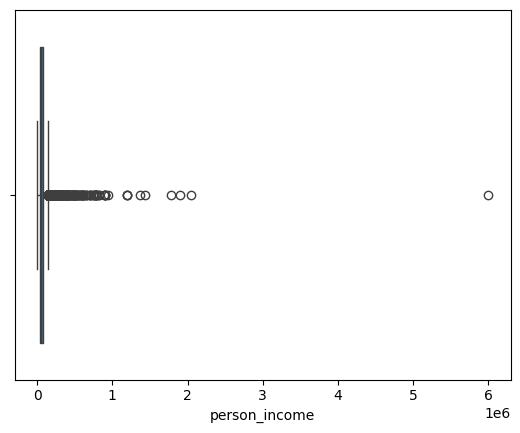

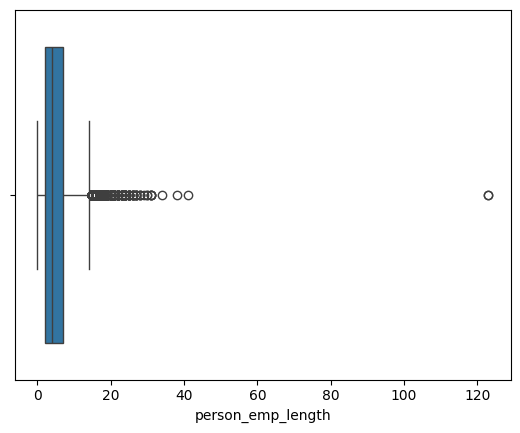

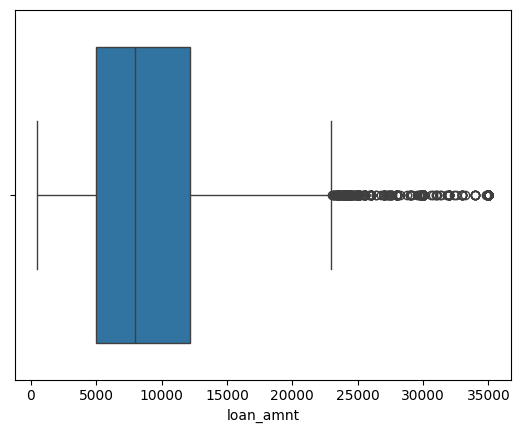

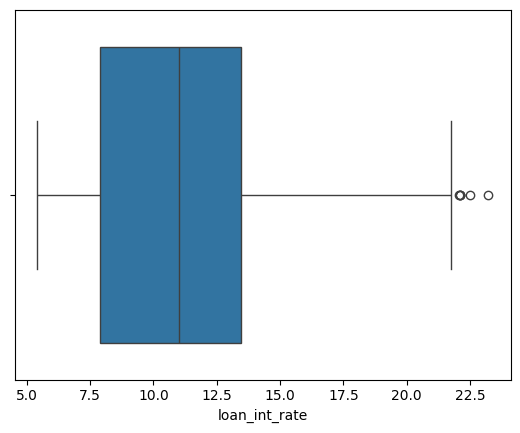

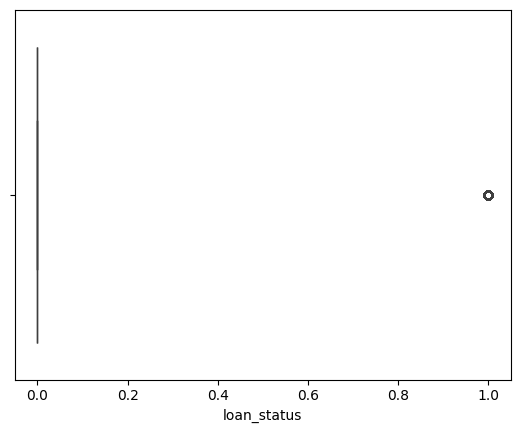

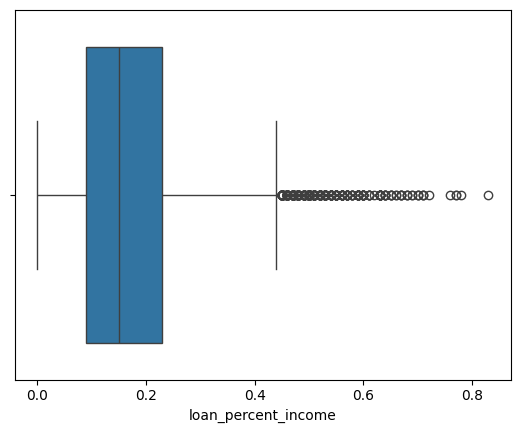

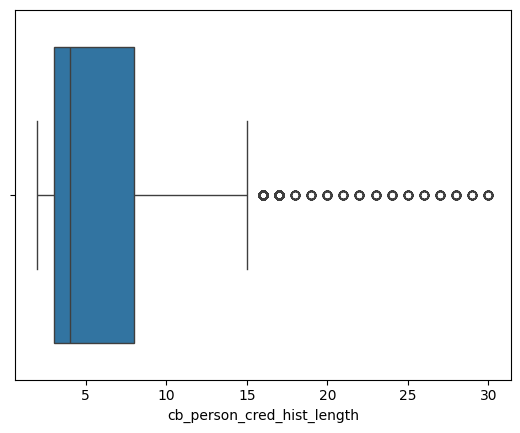

In [12]:
for i in num_cols:
    sns.boxplot(x=df[i])
    plt.show()

In [13]:
(df["person_age"] > 100).sum()

np.int64(5)

In [14]:
(df["person_emp_length"] > 60).sum()

np.int64(2)

<Axes: >

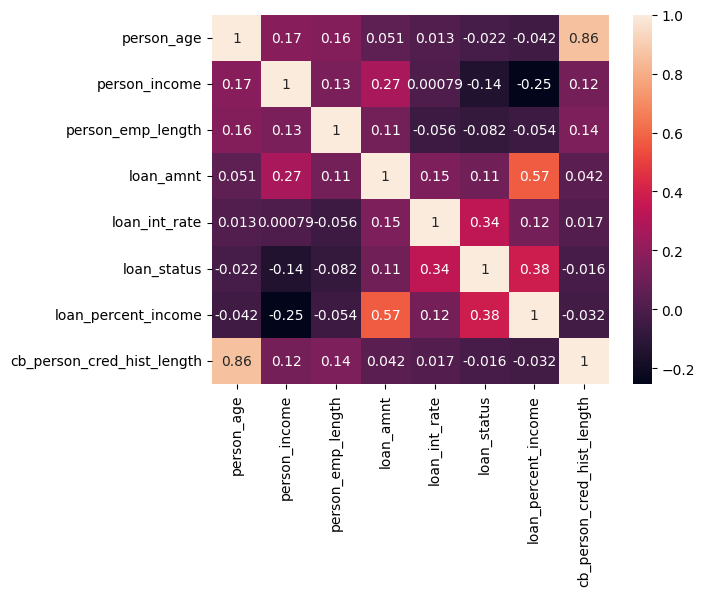

In [15]:
sns.heatmap(df.corr(numeric_only=True),annot = True)

# Data Validation and Outlier Handling

In [16]:
df_copy = df.copy()

In [17]:
print(df_copy.shape[0])
df_copy.drop_duplicates(inplace=True)
print(df_copy.shape[0])

32581
32416


In [18]:
df_copy = df_copy[df_copy["person_age"] >= 18]
df_copy = df_copy[df_copy["person_age"] <= 100]

df_copy = df_copy[df_copy["person_emp_length"] <= df_copy["person_age"]]
df_copy = df_copy[df_copy["person_emp_length"] <= 60]

# Feature,Target & Train-Test Split

In [19]:
X = df_copy.drop(columns='loan_status',axis=1)
y = df_copy["loan_status"]

In [20]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2,stratify=y)

In [21]:
new_num_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
cat_cols = ['person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file']

# Handle Class Imbalance

In [22]:
neg,pos = np.bincount(y_train)

scale_weights = neg/pos

# Data Preprocessing - Pipline & Column Transformer

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scaler',StandardScaler())
        ]),new_num_cols),
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value='Missing')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),cat_cols)
    ]
)

In [24]:
preprocessor_xg = ColumnTransformer(
    transformers=[
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median'))
        ]),new_num_cols),
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value='Missing')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),cat_cols)
    ]
)

# Cross-Validation

In [25]:
from sklearn.model_selection import StratifiedKFold,cross_validate

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring = {'roc_auc':'roc_auc','accuracy':'accuracy','precision':'precision','recall':'recall'}

# Logistic Regression

In [26]:
from sklearn.linear_model import LogisticRegression

lr_cv_pipline = Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(max_iter=1000,random_state=42,class_weight='balanced'))
])

lr_cv_pipline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

# XG Boost

In [27]:
from xgboost import XGBClassifier

xg_cv_pipline = Pipeline([
     ('preprocessor',preprocessor_xg),
     ('classifier',XGBClassifier(n_estimator=300,max_depth = 5,learning_rate=0.1,scale_pos_weight=scale_weights,random_state=42))
])
xg_cv_pipline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

In [28]:
for cv_name,pip in [("Logistic Regression",lr_cv_pipline),("XGBoost",xg_cv_pipline)]:
  cv_result = cross_validate(pip,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
  print(cv_name)
  print(f"ROC-AUC: {cv_result['test_roc_auc'].mean()}")
  print(f"Accuracy: {cv_result['test_accuracy'].mean()}")
  print(f"Precision: {cv_result['test_precision'].mean()}")
  print(f"Recall: {cv_result['test_recall'].mean()}")
  print()


Logistic Regression
ROC-AUC: 0.8705112830525306
Accuracy: 0.8115949542892269
Precision: 0.5448226008889892
Recall: 0.7781450872359963

XGBoost
ROC-AUC: 0.9393848243386111
Accuracy: 0.9086724038455642
Precision: 0.7913354492271174
Recall: 0.7856749311294765



# Evalution Helper Function


In [29]:
from sklearn.metrics._plot.precision_recall_curve import precision_recall_curve
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report

def eval_model(model_name,model,X_test,y_test,thresholds=None):
  y_pred = model.predict(X_test)
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if thresholds:
    y_pred = (y_pred_prob > thresholds).astype(int)
  else:
    y_pred = model.predict(X_test)

  accuracy = accuracy_score(y_test,y_pred)
  precision = precision_score(y_test,y_pred)
  recall = recall_score(y_test,y_pred)
  f1 = f1_score(y_test,y_pred)

  cm = confusion_matrix(y_test,y_pred)
  class_report = classification_report(y_test,y_pred)

  print(f"Accuracy: {accuracy:.2f}")
  # print(f"Best Threshold: {thresholds:.2f}")
  print(f"Precision: {precision:.2f}")
  print(f"Recall: {recall:.2f}")
  print(f"F1_Score: {f1:.2f}")
  print()
  print(f"{model_name} Classification Report")
  print(class_report)

  # Plotting Confusion Matrix
  sns.heatmap(cm,annot=True,fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Labels")
  plt.xlabel("Predicted Labels")
  plt.show()

  # Plotting ROC_AUC Curve
  precisions,recalls,threshold = precision_recall_curve(y_test,y_pred)
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.plot(recalls,precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.show()


# Baseline Model - Logistic Regression

In [30]:
baseline_model = Pipeline([
    ('Preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(class_weight='balanced'))
])
baseline_model.fit(X_train,y_train)


Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Accuracy: 0.82
Precision: 0.56
Recall: 0.79
F1_Score: 0.65

Baseline Logistic Model Classification Report
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



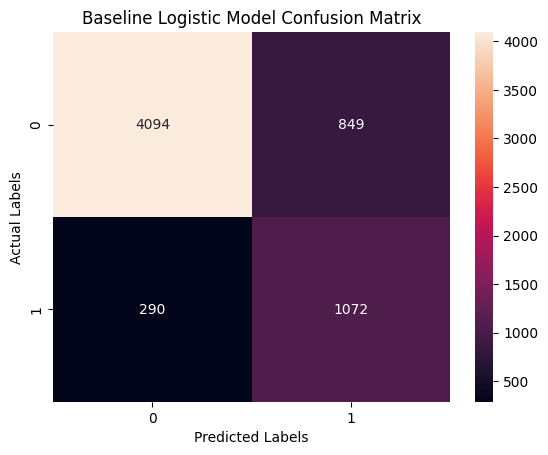

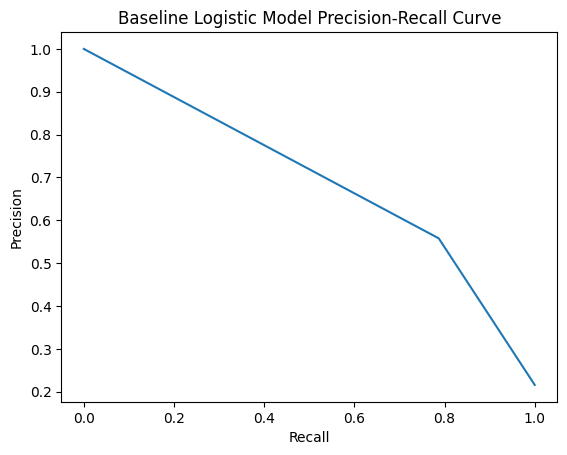

In [31]:
eval_model("Baseline Logistic Model",baseline_model,X_test,y_test)


In [32]:
xgb_model = Pipeline([
    ('Preprocessor',preprocessor_xg),
    ('Classifier',XGBClassifier(scale_pos_weight=scale_weights,learning_rate=0.1,random_state=42))
])

xgb_model.fit(X_train,y_train)

Pipeline(steps=[('Preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

Accuracy: 0.92
Precision: 0.82
Recall: 0.79
F1_Score: 0.81

XGBoost Classification Report
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



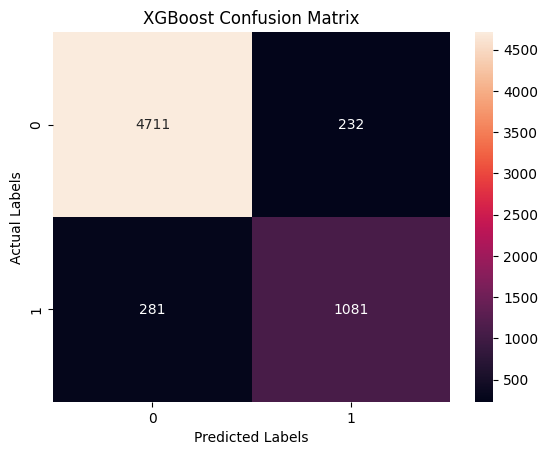

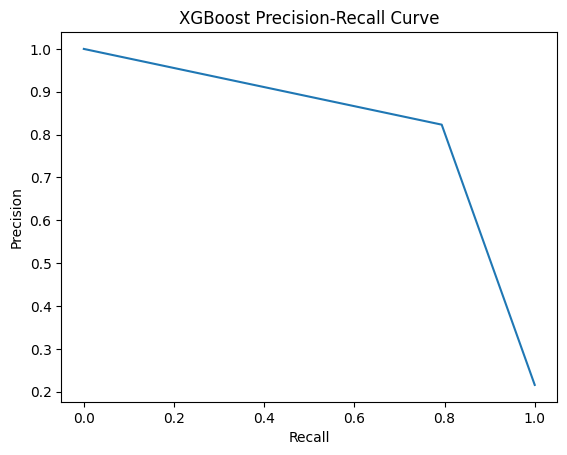

In [33]:
eval_model("XGBoost",xgb_model,X_test,y_test)

# HyperParameter Tunning

# XGBoost


In [34]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform,randint

param_grid = {
    "Classifier__n_estimators": randint(150,600),
    "Classifier__max_depth": randint(3,9),
    "Classifier__learning_rate":  uniform(0.01,0.5),
    "Classifier__colsample_bytree": uniform(0.6,0.4), # columns sampling
    "Classifier__subsample": uniform(0.6,0.4), #rows sampling
    "Classifier__min_child_weight": randint(1,10),
    "Classifier__gamma": uniform(0,5)
}

In [35]:
random_search = RandomizedSearchCV(
    xgb_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train,y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('Preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'Classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b2ac11d9590>,
                                        'Classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b2ac78b9fd0>,
                                        'Classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7b2ac11d9450>},
                   scoring='average_precision', verbose=1)

In [36]:
print(f"Score After tunning: {random_search.best_score_:.2f}")

Score After tunning: 0.90


In [37]:
random_search.best_params_

{'Classifier__colsample_bytree': np.float64(0.6236180611145276),
 'Classifier__gamma': np.float64(0.965010565430201),
 'Classifier__learning_rate': np.float64(0.16287054992566025),
 'Classifier__max_depth': 4,
 'Classifier__min_child_weight': 1,
 'Classifier__n_estimators': 583,
 'Classifier__subsample': np.float64(0.8650921836198289)}

Accuracy: 0.92
Precision: 0.81
Recall: 0.81
F1_Score: 0.81

XGBoost(Hyper) Classification Report
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.81      0.81      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



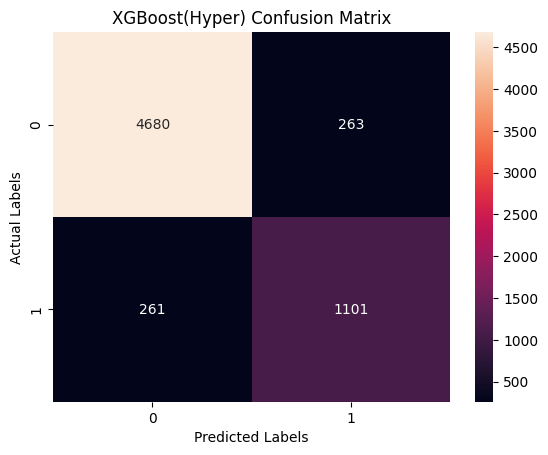

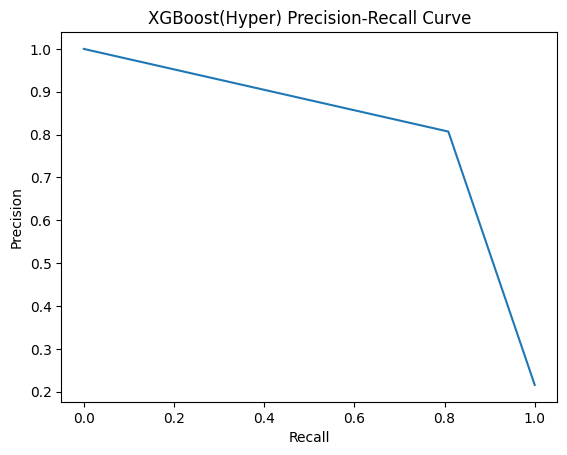

In [38]:
eval_model("XGBoost(Hyper)",random_search,X_test,y_test)

# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Define the pipeline
rf_model = Pipeline([
    ('Preprocessor', preprocessor_lr), # Random forest benefits from numeric preprocessing
    ('Classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
])

# Define parameter grid for RandomizedSearchCV
param_rf = {
    "Classifier__n_estimators": randint(100, 500),
    "Classifier__max_depth": [None] + list(randint(5, 30).rvs(5)),
    "Classifier__min_samples_split": randint(2, 20),
    "Classifier__min_samples_leaf": randint(1, 20),
    "Classifier__max_features": ['sqrt', 'log2', None]
}

# Define the search
random_forest = RandomizedSearchCV(
    rf_model,
    param_distributions=param_rf,
    n_iter=50,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1,
    random_state=42
)

# Fit the model
random_forest.fit(X_train, y_train)


Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('Preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income'...
                                        'Classifier__min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b4edc2656a0>,
                                        'Classifier__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b4edc213e30>,
                                        'Classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b4ee191bce0>},
                   random_state=42, scoring='average_precision', verbose=1)

Score After tunning: 0.88
{'Classifier__max_depth': np.int64(19), 'Classifier__max_features': None, 'Classifier__min_samples_leaf': 1, 'Classifier__min_samples_split': 6, 'Classifier__n_estimators': 330}
Accuracy: 0.93
Precision: 0.96
Recall: 0.73
F1_Score: 0.83

Random Forest(Hyper) Classification Report
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.96      0.73      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.94      0.86      0.89      6305
weighted avg       0.94      0.93      0.93      6305



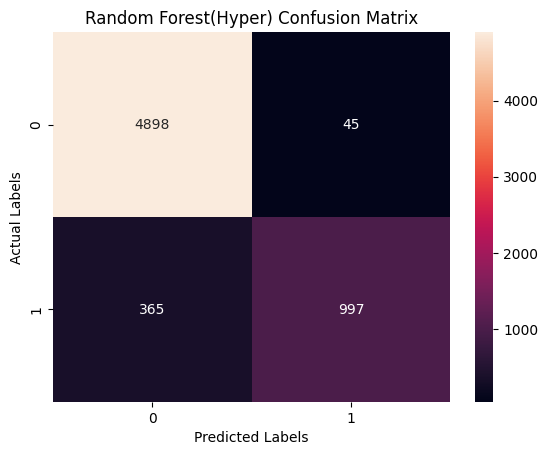

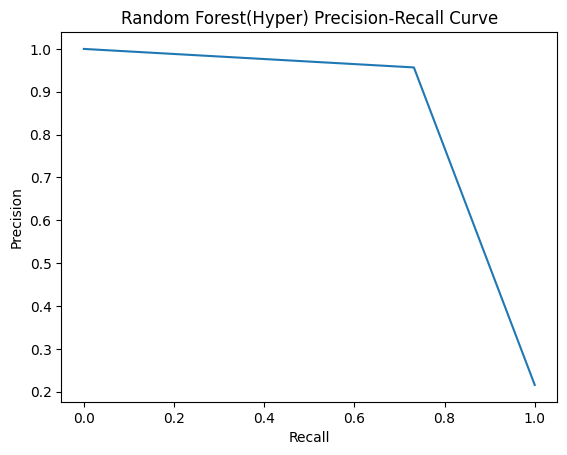

In [ ]:
print(f"Score After tunning: {random_forest.best_score_:.2f}")
print(random_forest.best_params_)
eval_model("Random Forest(Hyper)",random_forest,X_test,y_test)

# AdaBoost Hyperparameter Tuning

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Define the pipeline
adaboost_model = Pipeline([
    ('Preprocessor', preprocessor_lr),
    ('Classifier', AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced'), random_state=42))
])

# Define parameter grid for RandomizedSearchCV
param_ada = {
    "Classifier__n_estimators": randint(50, 300),
    "Classifier__learning_rate": uniform(0.01, 1.0),
    "Classifier__estimator__max_depth": randint(1, 5)
}

# Define the search
random_adaboost = RandomizedSearchCV(
    adaboost_model,
    param_distributions=param_ada,
    n_iter=50,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1,
    random_state=42
)

# Fit the model
random_adaboost.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('Preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income'...
                   param_distributions={'Classifier__estimator__max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b4edc235750>,
                                        'Classifier__learning_rate': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7b4ee1918180>,
                                        'Classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b4ee1922580>},
                   random_state=42, scoring='average_precision', verbose=1)

Score After tunning: 0.78
{'Classifier__estimator__max_depth': 4, 'Classifier__learning_rate': np.float64(0.1528668179219408), 'Classifier__n_estimators': 180}
Accuracy: 0.88
Precision: 0.73
Recall: 0.75
F1_Score: 0.74

AdaBoost(Hyper) Classification Report
              precision    recall  f1-score   support

           0       0.93      0.92      0.93      4943
           1       0.73      0.75      0.74      1362

    accuracy                           0.88      6305
   macro avg       0.83      0.83      0.83      6305
weighted avg       0.89      0.88      0.88      6305



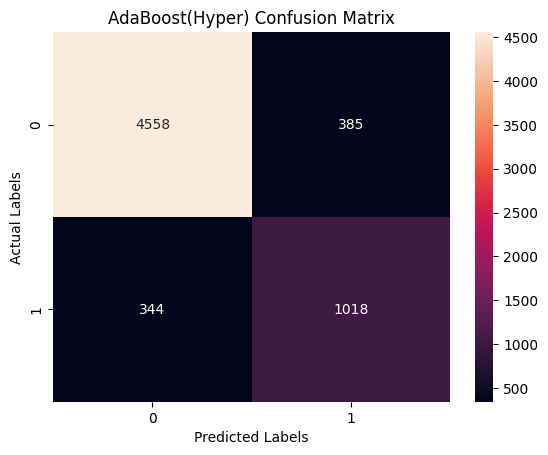

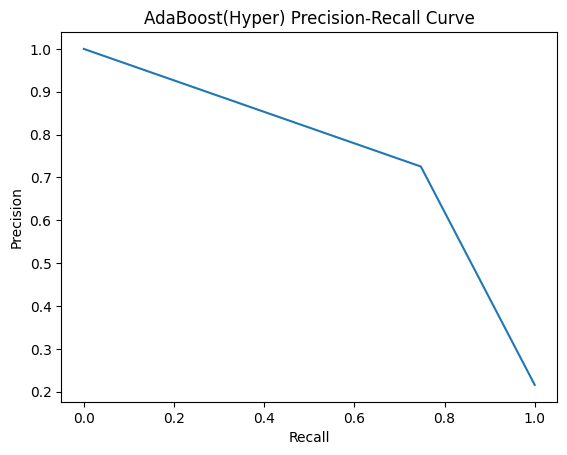

In [ ]:
print(f"Score After tunning: {random_adaboost.best_score_:.2f}")
print(random_adaboost.best_params_)
eval_model("AdaBoost(Hyper)",random_adaboost,X_test,y_test)

# Classification Threshold

Accuracy: 0.94
Precision: 0.98
Recall: 0.73
F1_Score: 0.83

XGBoost Classification Report
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      4943
           1       0.98      0.73      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.96      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305



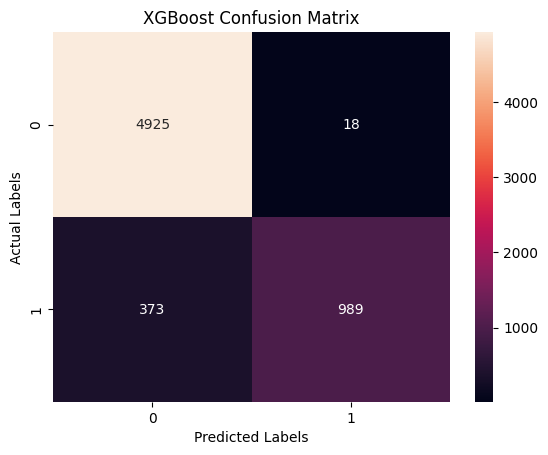

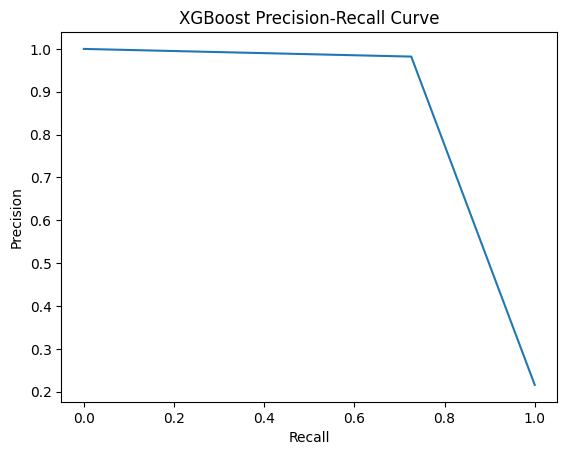

In [52]:
prob = xgb_model.predict_proba(X_test)[:,1]

precisions,recalls,thresholds = precision_recall_curve(y_test,prob)

f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

eval_model("XGBoost",xgb_model,X_test,y_test,best_threshold)


# Probability Calibration

In [53]:
from sklearn.calibration import calibration_curve,CalibratedClassifierCV

best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(best_model,method='sigmoid',cv=5)
calibrated_model.fit(X_train,y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('Preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.16287054992566025),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=4,
                                                                max_leaves=None,
                                                                min_child_weight=1,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=583,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [54]:
uncalibrated_prob = xgb_model.predict_proba(X_test)[:,1]
calibrated_prob = calibrated_model.predict_proba(X_test)[:,1]

print(uncalibrated_prob)
print(calibrated_prob)

[0.8254656  0.25111562 0.9782833  ... 0.48520026 0.07587515 0.05467961]
[0.73296636 0.02734765 0.9396697  ... 0.45931847 0.02791522 0.01617949]


In [55]:
actual_uncal,pred_uncal = calibration_curve(y_test,uncalibrated_prob,n_bins=10)
actual_cal,pred_cal = calibration_curve(y_test,calibrated_prob,n_bins=10)

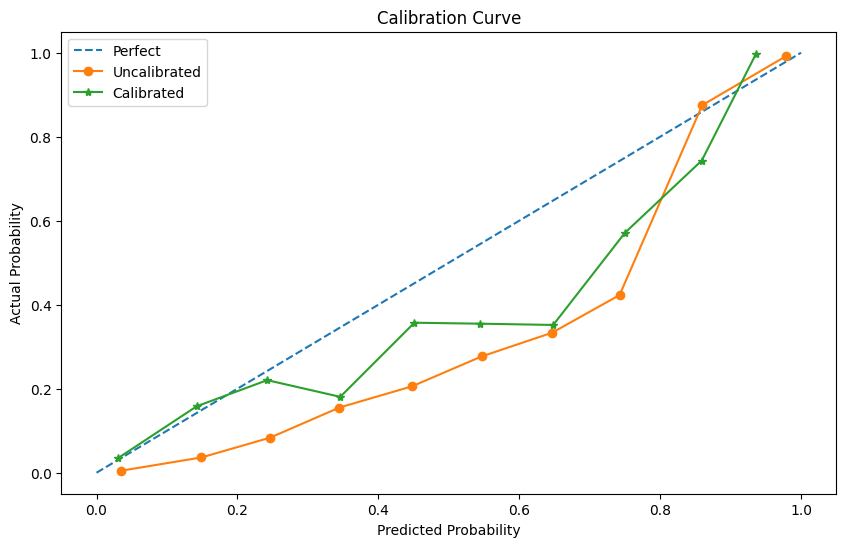

In [56]:
plt.figure(figsize=(10,6))
plt.plot([0,1],[0,1],linestyle="--",label="Perfect")
plt.plot(pred_uncal,actual_uncal,"o-",label="Uncalibrated")
plt.plot(pred_cal,actual_cal,"*-",label="Calibrated")
plt.legend()
plt.xlabel("Predicted Probability")
plt.ylabel("Actual Probability")
plt.title("Calibration Curve")
plt.show()

# SHAP

In [57]:
import shap

xgb_classifier = xgb_model.named_steps['Classifier']

X_test_transform = xgb_model.named_steps['Preprocessor'].transform(X_test)

feature_names = xgb_model.named_steps['Preprocessor'].get_feature_names_out()

X_test_df = pd.DataFrame(X_test_transform,columns=feature_names)

explainer = shap.TreeExplainer(xgb_classifier)

shap_values = explainer.shap_values(X_test_df)

# Global explanation

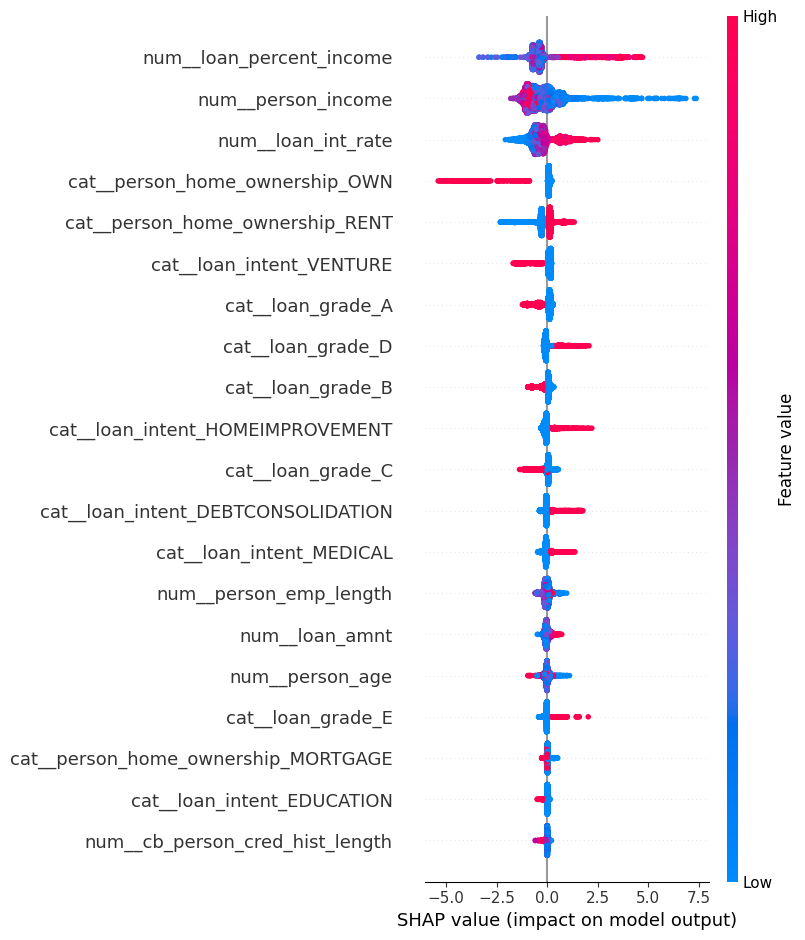

In [58]:
shap.summary_plot(shap_values, X_test_df)


# Local explanation

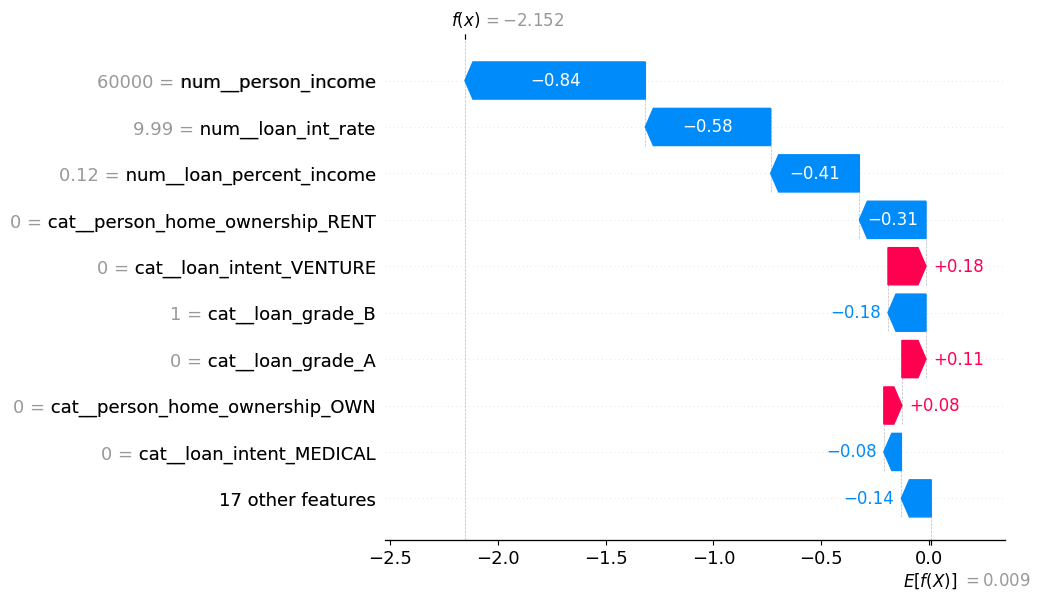

In [59]:
row_index = 5 # 5th applicant

shap.plots.waterfall(shap.Explanation(
    values = shap_values[row_index],
    base_values = explainer.expected_value,
    data = X_test_df.iloc[row_index],
    feature_names = feature_names
))


# Analyzing False Positive & False Negative

In [60]:
y_pred = random_search.predict(X_test)

result_df = X_test.copy()
result_df["Actual"] = y_test
result_df["Predicted"] = y_pred

false_possitive = result_df[(result_df["Actual"] == 0) & (result_df["Predicted"] == 1)]
false_negative = result_df[(result_df["Actual"] == 1) & (result_df["Predicted"] == 0)]

print(len(false_negative)) # False_negative  > False_positive
print(len(false_possitive))

261
263


# Save the Final Model

In [61]:
import joblib

In [62]:
joblib.dump(calibrated_model,"credit_risk_model.pkl")

['credit_risk_model.pkl']

In [67]:
calibrated_prob = calibrated_model.predict_proba(X_test)[:,1]

precisions,recalls,thresholds = precision_recall_curve(y_test,calibrated_prob)
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1[:-1])]
print(f"Best Threshold: {best_threshold}")


Best Threshold: 0.6638559844095433


In [68]:
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']